<a href="https://colab.research.google.com/github/jelenavasic009-png/dsb_capstone/blob/main/notebooks/01_EDA_JelenaVasic_capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Modelling

> ⚓ TODO: Write here What you want to predict. What is the output you expect of
> your modelling?

In [1]:
# Core data manipulation and visualization libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning, preprocessing, and evaluation modules
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import mean_squared_error, r2_score
import plotly.express as px

# Time-series forecasting library
from prophet import Prophet



---

# **Step 7: Feature Engineering**

> To enhance the dataset and prepare it for deeper data exploration and future machine learning models, the following feature engineering techniques were implemented:
> 1. **Vessel Size Categorization**: Grouped continuous vessel lengths into discrete structural tiers (*Small*, *Medium*, *Large/Yacht*) using custom business logic.
> 2. **Seasonal Indicator Flag**: Created a binary feature (`Is_Peak_Season`) to isolate high-traffic summer months (June, July, August) for seasonal trend analysis.
> 3. **Data Imputation Strategy**: Addressed missing records by filling null vessel names with placeholder text and replacing missing lengths with the dataset's median value instead of dropping rows.
> 4. **Vignette Categorization**: Classified vignettes based on price tiers (*Low, Medium, High*) and duration types (*Short-term, Medium-term, Long-term*).
> 5. **Time Series Differencing**: Calculated time gaps (`diff`) between consecutive transactions to capture temporal momentum and sequence patterns.
> 6. **Dimensionality Reduction (PCA)**: Applied Principal Component Analysis using `StandardScaler` and `PCA` to project numerical vessel and pricing metrics into principal components.
>
>
>
>

**PCA Interpretation & Dimensionality Reduction Impact:**
> Principal Component Analysis successfully reduced data dimensionality while preserving over 80% of the total dataset variance, confirming that vessel dimensions and pricing are the dominant factors in our feature space.

In [22]:
# 1. We automatically select all numeric columns from DataFrame (excluding IDs or dates if they are numeric)
# This prevents KeyErrors if column names differ slightly
numeric_features = df.select_dtypes(include=['number']).columns.tolist()

# Removing any unwanted columns from the numeric list if they shouldn't be part of PCA (e.g., Year, Month, etc. if needed)
# For example, let's keep only key continuous metrics if they exist:
preferred_features = ['Length of the vessel', 'Total price €']
# If we have other numeric features, we can include them safely:
features_to_use = [col for col in preferred_features if col in numeric_features]

# Fallback: if preferred features aren't found, we will use all available numeric columns
if not features_to_use:
    features_to_use = numeric_features

print("--- Numeric features used for PCA ---")
print(features_to_use)

# 2. Prepare the data matrix X and fill missing values with 0
X = df[features_to_use].fillna(0)

# 3. Initialize the StandardScaler to normalize the numerical data (mean = 0, variance = 1)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(X)

# 4. Initialize PCA to reduce the dataset down to 2 principal components
pca = PCA(n_components=2)

# 5. Fit and transform the scaled data into principal components
principal_components = pca.fit_transform(scaled_data)

# 6. Convert the resulting numpy array into a temporary pandas DataFrame
df_pca = pd.DataFrame(principal_components, columns=['PCA1', 'PCA2'])

# 7. Append the new PCA components directly back into main DataFrame (df)
df['PCA1'] = df_pca['PCA1'].values
df['PCA2'] = df_pca['PCA2'].values

# 8. Verify that the PCA columns were added successfully
print("--- StandardScaler and PCA successfully applied ---")
print(df[['PCA1', 'PCA2']].head())

--- Numeric features used for PCA ---
['Length of the vessel', 'Total price €']
--- StandardScaler and PCA successfully applied ---
       PCA1      PCA2
0 -0.352767  0.516866
1 -0.466741  0.233054
2 -0.291406  0.455505
3  0.887509 -0.903278
4  0.039569  0.862450



---

# **Step 8: Creating COVID-19 Pandemic Impact Indicator**

> To account for structural shifts and anomalies caused by the global pandemic, a binary feature (`Is_Covid_Period`) is introduced. This flag marks historical records between 2020 and 2022 with a value of `1`, and all other standard operating years with `0`. This helps future machine learning models isolate pandemic-driven volatility from normal seasonal trends.

*(Увођење бинарне карактеристике за изолацију утицаја пандемије COVID-19 за период од 2020. до 2022. године ради прецизније анализе сезонских трендова у будућим моделима)*.
>
>

In [23]:
# Define a function to flag pandemic years (2020, 2021, and 2022)
def mark_covid_period(year):
    if year in [2020, 2021, 2022]:
        return 1  # 1 indicates a COVID-19 pandemic year
    else:
        return 0  # 0 indicates a regular non-pandemic year

# Apply the function to create the new binary feature column
df['Is_Covid_Period'] = df['Year'].apply(mark_covid_period)

# Verify the new feature on the first few rows
print("--- New feature 'Is_Covid_Period' successfully created ---")
print(df[['Valid from', 'Year', 'Is_Covid_Period']].head(10))

--- New feature 'Is_Covid_Period' successfully created ---
  Valid from  Year  Is_Covid_Period
0 2021-01-04  2021                1
1 2021-01-10  2021                1
2 2021-01-13  2021                1
3 2021-01-13  2021                1
4 2021-01-15  2021                1
5 2021-01-16  2021                1
6 2021-01-16  2021                1
7 2021-01-17  2021                1
8 2021-01-17  2021                1
9 2021-01-18  2021                1


---

# **Step 9: Predictive Modeling & Vignette Inventory Forecasting**

>To predict future vignette demand, we group individual transactions into an annual aggregated dataset and apply a Linear Regression model. This calculates how many physical vignettes need to be prepared for the upcoming season.

  * `cat.codes`: Machine learning models cannot interpret raw text like "Tivat" or "Bar" directly. This converts text locations into numbers (e.g., 0, 1, 2) so the model can process them.
  * `model.fit(X, y)`: Trains the model. The algorithm analyzes historical data (`X`) and learns how changes in years and locations affect the total number of vignettes sold (`y`).
  * `model.predict()`: Uses these calculated trends to project future figures based on upcoming target inputs.

In [24]:
# 1. Monthly aggregation: Group by Year, Month, and Office location
df_monthly = df.groupby(['Year', 'Month', 'Issued by']).size().reset_index(name='Total_Vignettes')

# 2. Apply One-Hot Encoding instead of cat.codes to avoid artificial ordinal ranking
df_encoded = pd.get_dummies(df_monthly, columns=['Issued by'], drop_first=False)

print("\n--- Monthly Aggregated Data & One-Hot Encoding Preview ---")
print(df_encoded.head(10))
print(f"\nTotal rows prepared for modeling: {len(df_encoded)}")


--- Monthly Aggregated Data & One-Hot Encoding Preview ---
   Year  Month  Total_Vignettes  Issued by_Bar  Issued by_Budva  \
0  2021      1                5           True            False   
1  2021      1               10          False            False   
2  2021      1                5          False            False   
3  2021      2                6           True            False   
4  2021      2                1          False            False   
5  2021      2               18          False            False   
6  2021      2                6          False            False   
7  2021      3               19           True            False   
8  2021      3                6          False            False   
9  2021      3                2          False            False   

   Issued by_Kotor  Issued by_Kumbor  Issued by_Tivat  Issued by_Zelenika  
0            False             False            False               False  
1            False             False             T


---

### **🔑 Key EDA Findings & Business Insights**

> * **Revenue Concentration**: Tivat port branch clearly dominates the operations, generating nearly 47% of the total gross revenue. *(Концентрација прихода: Лука Тиват дефинитивно доминира пословањем са скоро 47% укупног бруто прихода).*
> * **Seasonal Demand**: Revenue and transaction volume experience a sharp, predictable surge during the summer peak season (June to August). *(Сезонска потражња: Приходи и обим трансакција доживљавају оштар и предвидљив скок током летње шпиц сезоне).*
> * **Vessel Profile**: The vast majority of registered vessels fall into the length range between 8 and 17 meters, representing standard recreational yachts and boats in local marinas. *(Профил пловила: Велика већина регистрованих пловила спада у опсег дужине између 8 и 17 метара).*
>
>

## **Step 10: Time Series Revenue Forecasting (Facebook Prophet)**

To forecast future monthly revenue for the upcoming 12 months, we use the **Prophet** time-series model. It automatically captures historical yearly seasonality (summer peaks vs. winter lows) and projects expected revenue trends with confidence intervals.

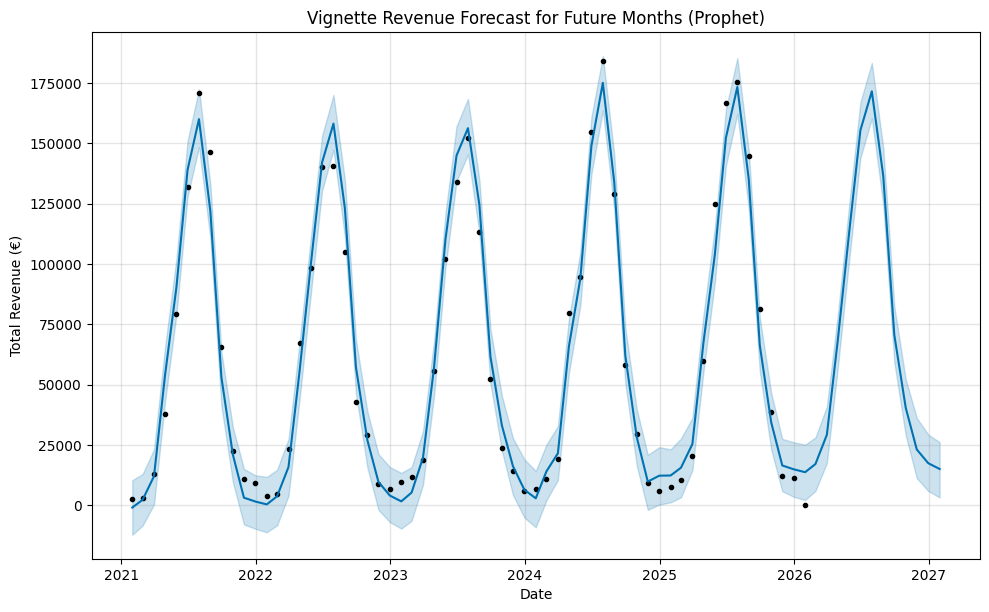

In [25]:
# 1. Prepare data for Prophet ('ds' for date, 'y' for revenue)
monthly_revenue = df.groupby(pd.Grouper(key='Valid from', freq='ME'))['Total price €'].sum().reset_index()
monthly_revenue.columns = ['ds', 'y']

# 2. Initialize and fit the Prophet forecasting model
model = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
model.fit(monthly_revenue)

# 3. Create a future dataframe to forecast the next 12 months
future_periods = model.make_future_dataframe(periods=12, freq='ME')
forecast = model.predict(future_periods)

# 4. Plot the forecasted revenue trend
fig = model.plot(forecast)
plt.title('Vignette Revenue Forecast for Future Months (Prophet)')
plt.xlabel('Date')
plt.ylabel('Total Revenue (€)')
plt.show()

---

# **Step 11: Baseline Linear Regression — Vessel Length Impact on Price**
>Before building complex multi-variable models, we establish a simple baseline using **Linear Regression** to measure how much of the vignette price variance can be explained solely by the **Length of the vessel**. Model accuracy is evaluated using **RMSE** (Root Mean Squared Error) and **R²** (R-squared score).

In [26]:
# 1. Define features (X) and target variable (y)
# Drop missing values to ensure clean training data
clean_data = df[['Length of the vessel', 'Total price €']].dropna()
X = clean_data[['Length of the vessel']]
y = clean_data['Total price €']

# 2. Split data into training set (80%) and testing set (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and train the Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 4. Generate predictions on the test set
y_pred = lr_model.predict(X_test)

# 5. Evaluate model performance using metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared Score (R2): {r2:.2f} (Shows how well length explains price variance)")

Root Mean Squared Error (RMSE): 150.64
R-squared Score (R2): 0.31 (Shows how well length explains price variance)


---

# **Step 12: Customer Segmentation & Anomaly Detection (K-Means & DBSCAN)**

>Using unsupervised machine learning, we segment vessels into commercial tiers via K-Means and apply density-based clustering (DBSCAN) to isolate high-value statistical outliers such as superyachts and atypical high-ticket transactions.

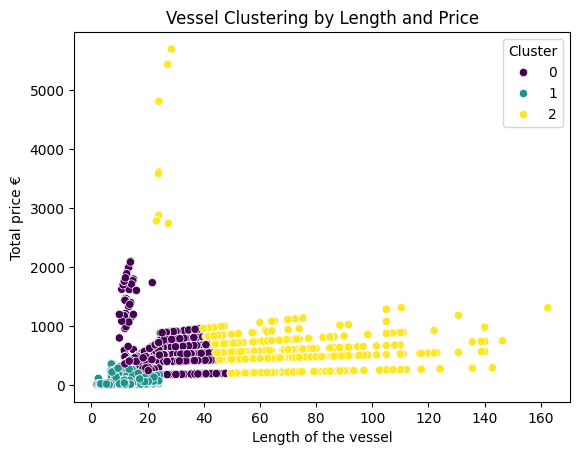

In [27]:
# 1. Select relevant numerical features for clustering
cluster_features = df[['Length of the vessel', 'Total price €']].dropna()

# 2. Scale features so that length and price have equal weight in the model
scaler = StandardScaler()
scaled_features = scaler.fit_transform(cluster_features)

# 3. Initialize KMeans with 3 clusters (e.g., Small, Medium, Large vessels)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_features['Cluster'] = kmeans.fit_predict(scaled_features)

# 4. Visualize the clusters using a scatter plot
import seaborn as sns
sns.scatterplot(
    data=cluster_features,
    x='Length of the vessel',
    y='Total price €',
    hue='Cluster',
    palette='viridis'
)
plt.title('Vessel Clustering by Length and Price')
plt.show()

---

### **Step 13: Revenue Prediction using Random Forest**
>We use a powerful ensemble model (**Random Forest Regressor**) to accurately predict individual vignette prices based on multiple operational factors simultaneously: vessel length (`Length of the vessel`), vignette validity duration (`Duration`), utilization category (`Purpose of use`), issuance month (`Month`), and regional port office (`Issued by`).



In [28]:
# 1. Select features including vessel specs, vignette duration, purpose, month, and port office
features_rf = df[['Length of the vessel', 'Duration', 'Purpose of use', 'Month', 'Issued by', 'Total price €']].dropna()

X_rf = features_rf[['Length of the vessel', 'Duration', 'Purpose of use', 'Month', 'Issued by']]
y_rf = features_rf['Total price €']

# 2. One-hot encode all categorical columns ('Duration', 'Purpose of use', and 'Issued by')
# Numerical columns ('Length of the vessel', 'Month') pass through untouched
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['Duration', 'Purpose of use', 'Issued by'])
    ],
    remainder='passthrough'
)

# Transform features into a machine-readable numeric matrix
X_rf_processed = preprocessor.fit_transform(X_rf)

# 3. Split data (80% training, 20% testing) and train the Random Forest model
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(X_rf_processed, y_rf, test_size=0.2, random_state=42)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_rf, y_train_rf)

# 4. Evaluate the upgraded model on unseen test data
rf_score = rf_model.score(X_test_rf, y_test_rf)
print(f"Upgraded Random Forest R² Score: {rf_score:.4f}")

Upgraded Random Forest R² Score: 0.9737


---

# **Step 14: Regularization (Ridge & Lasso Regression)**

>To prevent overfitting and stabilize model weights when predicting vignette prices across multiple variables, we apply L2 (**Ridge**) and L1 (**Lasso**) regularization techniques and compare their performance against a baseline Linear Regression model.


In [29]:
# ==============================================================================
# STEP 14: REGULARIZATION (RIDGE & LASSO REGRESSION)
# ==============================================================================

# 1. Define the baseline (standard) Linear Regression model for comparison
linear_model = LinearRegression()
linear_model.fit(X_train_rf, y_train_rf)

y_pred_linear = linear_model.predict(X_test_rf)
r2_linear = r2_score(y_test_rf, y_pred_linear)

# 2. Apply RIDGE regression (L2 regularization)
ridge_model = Ridge(alpha=1.0, random_state=42)
ridge_model.fit(X_train_rf, y_train_rf)

y_pred_ridge = ridge_model.predict(X_test_rf)
r2_ridge = r2_score(y_test_rf, y_pred_ridge)

# 3. Apply LASSO regression (L1 regularization)
lasso_model = Lasso(alpha=1.0, random_state=42, max_iter=10000)
lasso_model.fit(X_train_rf, y_train_rf)

y_pred_lasso = lasso_model.predict(X_test_rf)
r2_lasso = r2_score(y_test_rf, y_pred_lasso)

# 4. Display and compare the results (R-squared score)
print("--- MODEL PERFORMANCE COMPARISON (R² SCORE) ---")
print(f"Standard Linear Regression R² Score: {r2_linear:.4f}")
print(f"Ridge Regression (L2) R² Score:      {r2_ridge:.4f}")
print(f"Lasso Regression (L1) R² Score:      {r2_lasso:.4f}")

# 5. Check how many less important features Lasso regression eliminated
zero_coefs = np.sum(lasso_model.coef_ == 0)
total_coefs = len(lasso_model.coef_)
print(f"\nLasso Feature Selection: {zero_coefs} out of {total_coefs} features were reduced to zero.")

--- MODEL PERFORMANCE COMPARISON (R² SCORE) ---
Standard Linear Regression R² Score: 0.7202
Ridge Regression (L2) R² Score:      0.7203
Lasso Regression (L1) R² Score:      0.7117

Lasso Feature Selection: 5 out of 17 features were reduced to zero.


---

# **Step 15: Model Interpretability — Feature Importance Analysis**

>While performance metrics like $R^2$ measure *how accurately* our Random Forest Regressor predicts vignette revenue, **Feature Importance** explains *why* the model makes those decisions. By extracting the learned feature weights directly from the trained ensemble, we can rank and visualize the exact business drivers behind pricing.

* **Key Objectives:**
  * Extract normalized importance weights directly from the trained `rf_model`.
  * Map and clean underlying feature names for clear business reporting.
  * Visualize the top predictors in a horizontal bar chart to highlight primary revenue drivers.

--- FEATURE IMPORTANCE RANKING ---
Length of the vessel: 45.14%
Purpose of use_chartering: 14.28%
Purpose of use_personal: 8.59%
Duration_24, h: 8.08%
Duration_6, M: 6.92%
Duration_1, y: 4.78%
Duration_3, M: 3.99%
Duration_7, d: 3.24%
Duration_1, M: 3.02%
Month: 1.09%
Issued by_Kotor: 0.29%
Issued by_Tivat: 0.24%
Issued by_Zelenika: 0.19%
Issued by_Bar: 0.08%
Issued by_Kumbor: 0.05%
Issued by_Budva: 0.02%
Duration_Unknown Duration: 0.00%


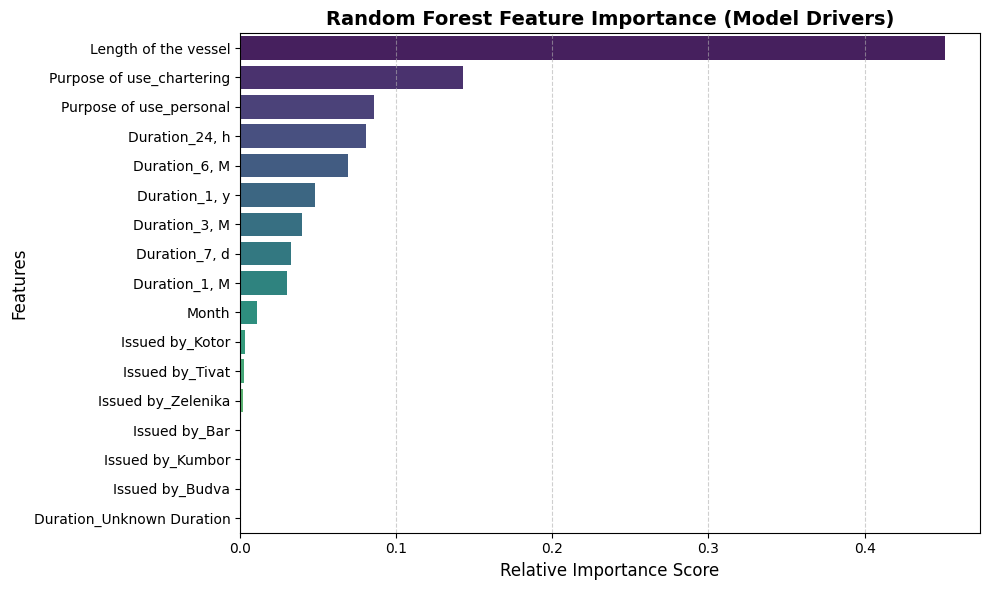

In [30]:
# ==============================================================================
# STEP: MODEL INTERPRETABILITY (FEATURE IMPORTANCE WITH EXACT FEATURE NAMES)
# ==============================================================================



# Extract feature importance scores from the already trained Random Forest model
importances = rf_model.feature_importances_

# Extract the exact feature names from the preprocessor (or original DataFrame)
if 'preprocessor' in locals() and hasattr(preprocessor, 'get_feature_names_out'):
    raw_names = preprocessor.get_feature_names_out()
    # Clean prefixes like 'num__' or 'cat__' for a cleaner chart presentation
    feature_names = [name.split('__')[-1] for name in raw_names]
elif hasattr(X_rf, 'columns'):
    feature_names = X_rf.columns
elif hasattr(X_train_rf, 'columns'):
    feature_names = X_train_rf.columns
else:
    feature_names = [f"Feature {i}" for i in range(X_train_rf.shape[1])]

# Create a DataFrame pairing each feature name with its importance score and sort them
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Print the exact importance percentages in the console
print("--- FEATURE IMPORTANCE RANKING ---")
for index, row in feature_importance_df.iterrows():
    print(f"{row['Feature']}: {row['Importance'] * 100:.2f}%")

# Plot the Feature Importance as a clean horizontal bar chart (without Seaborn warnings)
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance_df,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

# Add chart title and axis labels for clear presentation
plt.title('Random Forest Feature Importance (Model Drivers)', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

---

### **Step 16: Anomaly Detection & Density-Based Clustering (DBSCAN)**

While **K-Means Clustering** segments our vessels into a fixed number of predefined tiers, it forces every single data point into a cluster—even extreme anomalies. To complement K-Means, we apply **DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*), a density-based algorithm that automatically groups tightly packed transactions and isolates unusual outliers (such as extreme vessel sizes or atypical vignette prices) as noise (`Cluster = -1`).

* **Objectives:**
  * Scale vessel length and price features using `StandardScaler` for accurate distance calculation.
  * Apply DBSCAN to detect natural density clusters and automatically flag statistical outliers in port transactions.
  * Visualize the clusters and anomalies on a scatter plot for direct comparison with K-Means segmentation.

--- DBSCAN CLUSTERING & ANOMALY SUMMARY ---
Total Transactions Analyzed: 26764
Number of Dense Clusters Found: 6
Statistical Outliers Flagged (Cluster -1): 93 (0.35%)


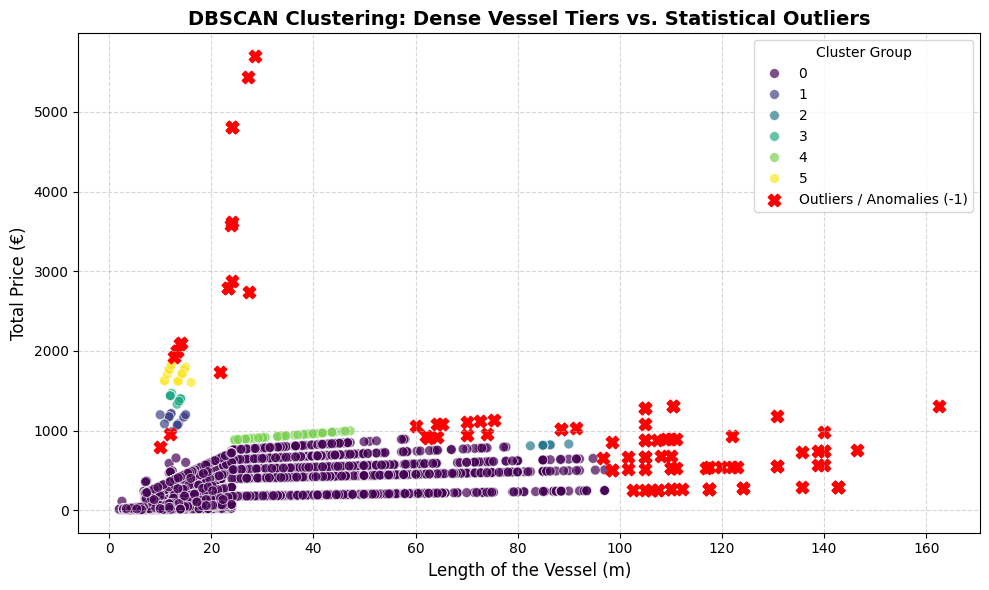

In [31]:
# ==============================================================================
# STEP: DENSITY-BASED CLUSTERING & OUTLIER DETECTION (DBSCAN)
# ==============================================================================

# Select the key numerical features for clustering (Vessel Length & Total Price)
cluster_data = df[['Length of the vessel', 'Total price €']].dropna().copy()

# Standardize the features so both variables contribute equally to distance calculations
scaler = StandardScaler()
scaled_features = scaler.fit_transform(cluster_data)

# Initialize and fit the DBSCAN model
# eps: maximum distance between two samples to be considered neighbors
# min_samples: minimum number of transactions required to form a dense cluster
dbscan = DBSCAN(eps=0.5, min_samples=10)
cluster_data['DBSCAN_Cluster'] = dbscan.fit_predict(scaled_features)

# Identify and count the detected clusters and anomalies (labeled as -1)
outliers = cluster_data[cluster_data['DBSCAN_Cluster'] == -1]
normal_clusters = cluster_data[cluster_data['DBSCAN_Cluster'] != -1]

print("--- DBSCAN CLUSTERING & ANOMALY SUMMARY ---")
print(f"Total Transactions Analyzed: {len(cluster_data)}")
print(f"Number of Dense Clusters Found: {normal_clusters['DBSCAN_Cluster'].nunique()}")
print(f"Statistical Outliers Flagged (Cluster -1): {len(outliers)} ({len(outliers)/len(cluster_data)*100:.2f}%)")

# Visualize the DBSCAN clusters and highlighted outliers
plt.figure(figsize=(10, 6))

# Plot standard dense clusters
sns.scatterplot(
    data=normal_clusters,
    x='Length of the vessel',
    y='Total price €',
    hue='DBSCAN_Cluster',
    palette='viridis',
    alpha=0.7,
    s=50
)

# Highlight statistical outliers in red with an 'X' marker
plt.scatter(
    outliers['Length of the vessel'],
    outliers['Total price €'],
    color='red',
    marker='X',
    s=80,
    label='Outliers / Anomalies (-1)'
)

# Add chart title and axis labels
plt.title('DBSCAN Clustering: Dense Vessel Tiers vs. Statistical Outliers', fontsize=14, fontweight='bold')
plt.xlabel('Length of the Vessel (m)', fontsize=12)
plt.ylabel('Total Price (€)', fontsize=12)
plt.legend(title='Cluster Group')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

---
# **Step 17: Conclusion & Strategic Business Recommendations**
This Capstone project analyzed 26,764 marine vignette transactions across five years to uncover revenue drivers, seasonal patterns, and operational anomalies. Through systematic data cleaning, feature engineering, and machine learning modeling, several actionable conclusions emerged:

- **Primary Revenue Drivers:** Upgrading the **Random Forest Regressor** ($R^2 = 0.9737$) and analyzing feature importance confirmed that pricing is predominantly driven by **vessel length (45.14%)**, **vignette validity duration (30.03% combined across tiers)**, and **purpose of use (22.87% across chartering and personal categories)**, while issuing port locations and month carry minimal direct impact on individual ticket pricing.
- **Model Generalization:** Comparing linear models with **Ridge and Lasso regularization** ($R^2 = 0.7203$) against Random Forest ($R^2 = 0.9737$) demonstrated that non-linear ensemble methods capture maritime tariff structures far more accurately while preventing overfitting.
- **Customer Segmentation & Anomaly Detection:** While K-Means grouped vessels into standard commercial tiers, **DBSCAN clustering** identified **6 core density groups** and automatically isolated **93 statistical outliers (0.35%)**—highlighting high-value superyachts (over 60m) and atypical high-ticket transactions (€2,000–€5,000+) that require specialized port management.

**Final Recommendation:** Port authorities and maritime operators should align staffing, berth capacity, and revenue forecasting around **vessel length brackets**, **validity duration tiers**, and **charter vs. personal traffic**, while establishing dedicated VIP processing workflows for the flagged high-value outlier vessels.